# Chapitre 9 - Cours 2 : arbres de régression et de classification (CART)

Ce notebook suit la section 9.2 du livre. Les arbres **partitionnent l'espace des
entrées en rectangles** et ajustent un modèle très simple (une constante) dans chacun.
Nous allons :

1. décrire les partitions binaires récursives (figure 9.2) ;
2. faire croître un arbre de **régression** (critère des moindres carrés, éq. (9.13)) ;
3. l'**élaguer** par le critère coût-complexité (éq. (9.16)) ;
4. passer à la **classification** : mesures d'impureté de Gini, d'entropie et d'erreur
   (figure 9.3) ;
5. discuter les autres questions pratiques (variables qualitatives, pertes, instabilité) ;
6. reproduire l'exemple **spam** : validation croisée (figure 9.4), arbre élagué
   (figure 9.5), table 9.3 et courbes ROC (figure 9.6).

Tout est implémenté à la main dans la classe `ArbreCART` du module `esl/ch09_arbres.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch09_arbres import (ArbreCART, cart_cv, impurity, trace_arbre, roc_curve,
                             auc, GAM, SPAM_NAMES)

set_style()
rng = np.random.RandomState(0)

## 1. Partitions binaires récursives (figure 9.2)

Considérons deux entrées $X_1, X_2\in[0,1]$. Une partition quelconque du carré par des
segments parallèles aux axes (panneau de gauche ci-dessous) produit des régions
difficiles à décrire. On se restreint donc aux partitions **binaires récursives** : on
coupe d'abord l'espace en deux selon une règle $X_j\le s$, puis on recoupe chacune des
deux moitiés, et ainsi de suite (panneau de droite).

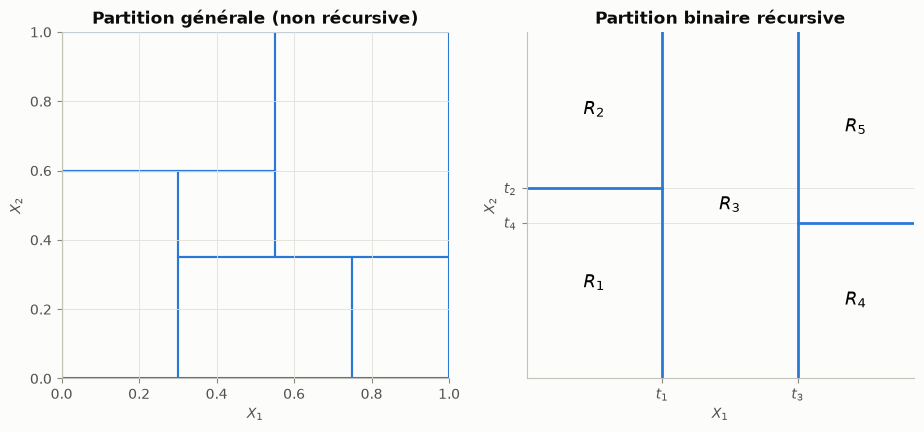

In [2]:
t1, t2, t3, t4 = 0.35, 0.55, 0.7, 0.45
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ax = axes[0]
for (x0, y0, w, h) in [(0, 0, .3, .6), (0, .6, .55, .4), (.3, 0, .45, .35), (.3, .35, .25, .25),
                       (.55, .35, .45, .65), (.75, 0, .25, .35)]:
    ax.add_patch(Rectangle((x0, y0), w, h, fill=False, lw=1.5, ec=BLUE))
ax.set(title="Partition générale (non récursive)", xlabel="$X_1$", ylabel="$X_2$",
       xlim=(0, 1), ylim=(0, 1))
ax = axes[1]
ax.plot([t1, t1], [0, 1], color=BLUE)
ax.plot([0, t1], [t2, t2], color=BLUE)
ax.plot([t3, t3], [0, 1], color=BLUE)
ax.plot([t3, 1], [t4, t4], color=BLUE)
for nom, (a, b) in {"$R_1$": (t1 / 2, t2 / 2), "$R_2$": (t1 / 2, (1 + t2) / 2),
                    "$R_3$": ((t1 + t3) / 2, .5), "$R_4$": ((1 + t3) / 2, t4 / 2),
                    "$R_5$": ((1 + t3) / 2, (1 + t4) / 2)}.items():
    ax.text(a, b, nom, ha="center", va="center", fontsize=13)
ax.set(title="Partition binaire récursive", xlabel="$X_1$", ylabel="$X_2$",
       xlim=(0, 1), ylim=(0, 1), xticks=[t1, t3], xticklabels=["$t_1$", "$t_3$"],
       yticks=[t4, t2], yticklabels=["$t_4$", "$t_2$"])
plt.show()

La partition de droite est obtenue ainsi : on coupe en $X_1=t_1$ ; la région
$X_1\le t_1$ est coupée en $X_2=t_2$ ; la région $X_1>t_1$ est coupée en $X_1=t_3$ ;
enfin la région $X_1>t_3$ est coupée en $X_2=t_4$. On obtient cinq régions
$R_1,\dots,R_5$ et le modèle (éq. (9.9))
$$\hat f(X) = \sum_{m=1}^5 c_m\,\mathbb 1\{(X_1,X_2)\in R_m\}.$$

Le même modèle se représente par un **arbre binaire** : on part de la racine (toutes les
données), une observation vérifiant la condition d'un nœud va à gauche, sinon à droite ;
les **feuilles** (nœuds terminaux) sont les régions $R_m$.

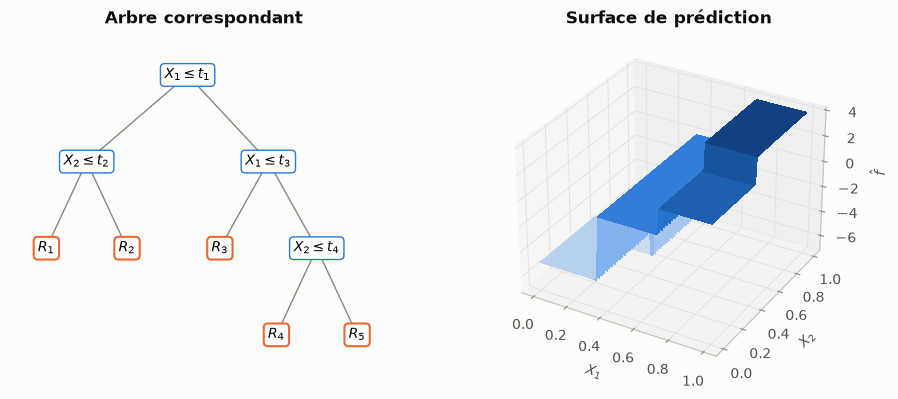

In [3]:
fig = plt.figure(figsize=(11, 4.5))
ax = fig.add_subplot(1, 2, 1)
noeuds = {"r": (2, 3, r"$X_1\leq t_1$"), "a": (0.75, 2, r"$X_2\leq t_2$"),
          "b": (3, 2, r"$X_1\leq t_3$"), "c": (3.6, 1, r"$X_2\leq t_4$")}
feuilles = {"R1": (0.25, 1), "R2": (1.25, 1), "R3": (2.4, 1), "R4": (3.1, 0), "R5": (4.1, 0)}
aretes = [("r", "a"), ("r", "b"), ("a", "R1"), ("a", "R2"), ("b", "R3"), ("b", "c"),
          ("c", "R4"), ("c", "R5")]
pos = {k: v[:2] for k, v in noeuds.items()} | feuilles
for u, v in aretes:
    ax.plot(*zip(pos[u], pos[v]), color=GRAY, lw=1)
for k, (x0, y0, lab) in noeuds.items():
    ax.text(x0, y0, lab, ha="center", va="center",
            bbox=dict(boxstyle="round", fc="white", ec=BLUE))
for k, (x0, y0) in feuilles.items():
    ax.text(x0, y0, "$R_%s$" % k[1], ha="center", va="center",
            bbox=dict(boxstyle="round", fc="white", ec=ORANGE, lw=1.5))
ax.set(xlim=(-0.2, 4.6), ylim=(-0.5, 3.5), title="Arbre correspondant")
ax.axis("off")

ax3 = fig.add_subplot(1, 2, 2, projection="3d")
g = np.linspace(0, 1, 80)
G1, G2 = np.meshgrid(g, g)
c = {1: -5, 2: -7, 3: 0, 4: 2, 5: 4}
Z = np.where(G1 <= t1, np.where(G2 <= t2, c[1], c[2]),
             np.where(G1 <= t3, c[3], np.where(G2 <= t4, c[4], c[5])))
ax3.plot_surface(G1, G2, Z, cmap=SEQ, linewidth=0, antialiased=False)
ax3.set(xlabel="$X_1$", ylabel="$X_2$", zlabel=r"$\hat f$", title="Surface de prédiction")
plt.show()

Les valeurs $c_1=-5$, $c_2=-7$, $c_3=0$, $c_4=2$, $c_5=4$ sont celles choisies par le
livre. L'arbre est **très lisible** : avec plus de deux entrées, on ne peut plus dessiner
la partition, mais l'arbre se lit toujours de la même façon (« si… alors… »).

## 2. Arbres de régression

### La constante optimale dans une région

On dispose de $N$ observations $(x_i,y_i)$, $x_i\in\mathbb R^p$. Supposons la partition
$R_1,\dots,R_M$ fixée et le modèle $f(x)=\sum_m c_m\mathbb 1(x\in R_m)$ (éq. (9.10)). Le
critère des moindres carrés se découpe en une somme sur les régions :
$$\sum_{i=1}^N (y_i - f(x_i))^2 = \sum_{m=1}^M \sum_{x_i\in R_m}(y_i-c_m)^2 .$$
Chaque terme ne dépend que de $c_m$ ; c'est un polynôme du second degré en $c_m$ dont la
dérivée $-2\sum_{x_i\in R_m}(y_i-c_m)$ s'annule en la **moyenne** de la région
(éq. (9.11)) :
$$\hat c_m = \mathrm{ave}(y_i \mid x_i\in R_m).$$

### Recherche gloutonne des coupures

Trouver la meilleure partition parmi **toutes** les partitions binaires est
combinatoirement impossible. On procède de façon **gloutonne** : pour une variable de
coupure $j$ et un seuil $s$, on définit les deux demi-espaces (éq. (9.12))
$$R_1(j,s)=\{X\mid X_j\le s\},\qquad R_2(j,s)=\{X\mid X_j>s\},$$
et l'on cherche (éq. (9.13))
$$\min_{j,\,s}\Big[\min_{c_1}\sum_{x_i\in R_1(j,s)}(y_i-c_1)^2 + \min_{c_2}\sum_{x_i\in
R_2(j,s)}(y_i-c_2)^2\Big].$$
D'après ce qui précède, les minimums intérieurs sont atteints en les moyennes des deux
demi-espaces (éq. (9.14)).

**Pourquoi est-ce rapide ?** Pour une variable $j$, on trie les $x_{ij}$. Seuls $N-1$
seuils sont à essayer (entre deux valeurs consécutives). La somme des carrés d'un groupe
s'écrit $\sum y_i^2 - (\sum y_i)^2/n$ : avec des **sommes cumulées** de $y_i$ et de
$y_i^2$ dans l'ordre trié, on obtient le critère pour tous les seuils en $O(N)$
opérations après le tri. En balayant les $p$ variables, on trouve la meilleure coupure
$(j,s)$ en $O(pN\log N)$.

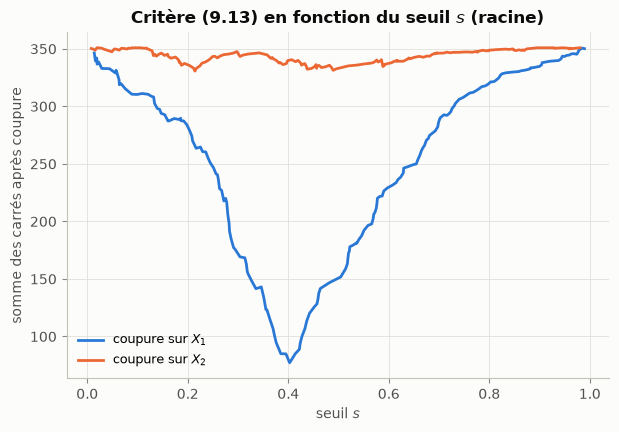

In [4]:
N = 200
Xr = rng.uniform(0, 1, (N, 2))
fr = np.where(Xr[:, 0] <= 0.4, np.where(Xr[:, 1] <= 0.6, -1.0, 0.5), 2.0)
yr = fr + 0.4 * rng.randn(N)

fig, ax = plt.subplots(figsize=(7, 4.5))
for j in range(2):
    o = np.argsort(Xr[:, j])
    xs, ys = Xr[o, j], yr[o]
    n = np.arange(1, N)
    S1, S2 = np.cumsum(ys)[:-1], np.cumsum(ys ** 2)[:-1]
    rss = (S2 - S1 ** 2 / n) + ((ys ** 2).sum() - S2 - (ys.sum() - S1) ** 2 / (N - n))
    ax.plot(0.5 * (xs[1:] + xs[:-1]), rss, color=COLORS[j], label="coupure sur $X_%d$" % (j + 1))
ax.set(title="Critère (9.13) en fonction du seuil $s$ (racine)",
       xlabel="seuil $s$", ylabel="somme des carrés après coupure")
ax.legend()
plt.show()

La meilleure coupure de la racine porte sur $X_1$ près de $0.4$, conformément à la
fonction simulée $f$ (constante par morceaux à trois régions). Faisons croître l'arbre
jusqu'à 3 feuilles et traçons la partition obtenue.

In [5]:
arbre_r = ArbreCART(task="regression", max_leaves=3).fit(Xr, yr)
print(arbre_r.describe(names=["X1", "X2"]))

X1 < 0.4027
  X2 < 0.6012
    -> moyenne=-1.078
  X2 > 0.6012
    -> moyenne=0.489
X1 > 0.4027
  -> moyenne=1.964


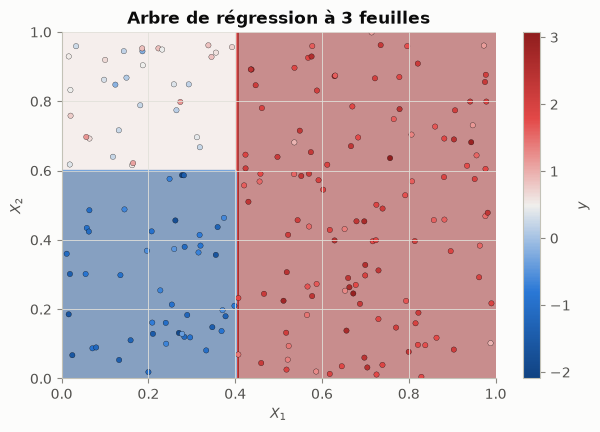

In [6]:
xx, yy = np.meshgrid(np.linspace(0, 1, 200), np.linspace(0, 1, 200))
zz = arbre_r.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(7, 4.5))
cs = ax.contourf(xx, yy, zz, levels=20, cmap=DIV, alpha=0.5)
sc = ax.scatter(Xr[:, 0], Xr[:, 1], c=yr, cmap=DIV, s=15, edgecolor="k", lw=0.2)
fig.colorbar(sc, ax=ax, label="$y$")
ax.set(title="Arbre de régression à 3 feuilles", xlabel="$X_1$", ylabel="$X_2$")
plt.show()

## 3. Taille de l'arbre et élagage coût-complexité

Un arbre trop grand sur-apprend, un arbre trop petit manque la structure : la **taille**
est le paramètre de complexité. S'arrêter dès qu'une coupure n'apporte pas assez est
une mauvaise idée (« myopie ») : une coupure en apparence inutile peut préparer une très
bonne coupure en dessous (penser à un « ou exclusif »). La stratégie de CART est donc :

1. faire croître un **grand arbre** $T_0$ (on ne s'arrête que lorsque les nœuds sont très
   petits, par exemple moins de 5 observations) ;
2. l'**élaguer**.